Ejemplo en el que se entrena una GAN para que cree puntos (x, y) dentro del segmento definido por los puntos (2.5, 2.5) y (7.5, 7.5).


In [ ]:
"""
Author: Jamal Toutouh (www.jamal.es)

It contains the code to show an example about using GAN.
In this case, the GAN is used to generate 2D points (x, y) inside the line
defined by the points between (2.5, 2.5) and (7.5, 7.5).
"""

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Variable

Definimos los datos reale

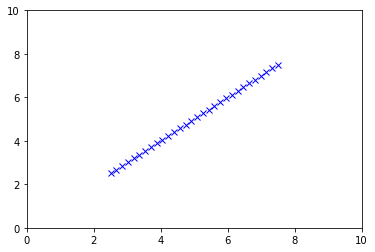

In [ ]:
# Data load and transformation
data_to_show=30


def plot_samples(real_data, fake_data=None, epoch=None):
    plt.xlim(0, 10)
    plt.ylim(0, 10)
    real_data_to_show = real_data.permute(-1, 0).detach().numpy()
    plt.plot(real_data_to_show[0], real_data_to_show[1], 'x', color='blue')

    if not fake_data is None:
      fake_data_to_show = fake_data.permute(-1, 0).detach().numpy()
      plt.plot(fake_data_to_show[0], fake_data_to_show[1], 'o', color='red')
    else:
      epoch = "real"

    plt.savefig('02-2d-line-gan-data-{}.png'.format(epoch))
    plt.show()


def get_data_samples(batch_size):
    points_x = np.linspace(2.5, 7.5, batch_size)
    points = np.array([[x, x] for x in points_x])
    return torch.from_numpy(points).float()

samples_to_plot = get_data_samples(data_to_show)
plot_samples(samples_to_plot)


Clase que define el generador

In [ ]:
class Generator(nn.Module):
    """
    Class that defines the the Generator Neural Network
    """
    def __init__(self, input_size, hidden_size, output_size):
        super(Generator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, hidden_size),
            nn.SELU(),
            nn.Linear(hidden_size, output_size),
            nn.SELU(),
        )

    def forward(self, x):
        x = self.net(x)
        return x

Clase que define el discriminador

In [ ]:
class Discriminator(nn.Module):
    """
    Class that defines the the Discriminator Neural Network
    """
    def __init__(self, input_size, hidden_size, output_size):
        super(Discriminator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ELU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ELU(),
            nn.Linear(hidden_size, output_size),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.net(x)
        return x

Función que crea los vectores del espacio latente que leerá el generador para crear los datos

In [ ]:
def read_latent_space(size):
    """
    Creates a tensor with random values fro latent space  with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with random values (z) with shape = size
    """
    z = torch.rand(size,30)
    if torch.cuda.is_available(): return z.cuda()
    return z

Función auxiliar para mostrar la evolución de la función de pérdida del  generador y el discriminador

In [ ]:
def plot_loss_evolution(discriminator_loss, generator_loss):
    x = range(len(discriminator_loss)) if len(discriminator_loss) > 0 else range(len(generator_loss))
    if len(discriminator_loss) > 0: plt.plot(x, discriminator_loss, '-b', label='Discriminator loss')
    if len(generator_loss) > 0: plt.plot(x, generator_loss, ':r', label='Generator loss')
    plt.legend()
    plt.savefig('02-2d-line-gan-loss.png')
    plt.show()

Funciones para crear las etiquetas de dato real *real_data_target* y dato falso *fake_data_target* que emplea el discriminador para calcular la función de pérdida

In [ ]:
def real_data_target(size):
    """
    Creates a tensor with the target for real data with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with real label value (ones) with shape = size
    """
    data = Variable(torch.ones(size, 1))
    if torch.cuda.is_available(): return data.cuda()
    return data


def fake_data_target(size):
    """
    Creates a tensor with the target for fake data with shape = size
    :param size: Size of the tensor (batch size).
    :return: Tensor with fake label value (zeros) with shape = size
    """
    data = Variable(torch.zeros(size, 1))
    if torch.cuda.is_available(): return data.cuda()
    return data

Función principal que define el entrenamiento de la GAN

Dataset loaded...
Starting adversarial GAN training for 40 epochs.


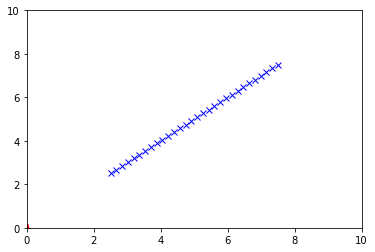

Epoch=0, Discriminator loss=2.3293375372886658, Generator loss=0.5815754532814026


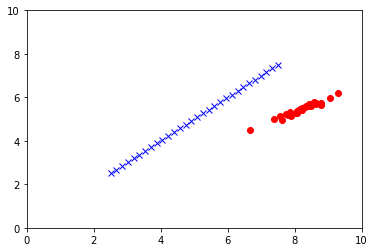

Epoch=1, Discriminator loss=1.901886522769928, Generator loss=0.47738227248191833


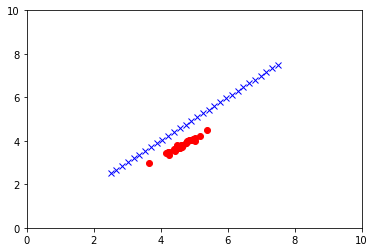

Epoch=2, Discriminator loss=1.1131301522254944, Generator loss=0.9163967370986938


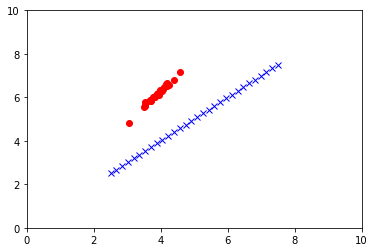

Epoch=3, Discriminator loss=1.3527979254722595, Generator loss=0.7360294461250305


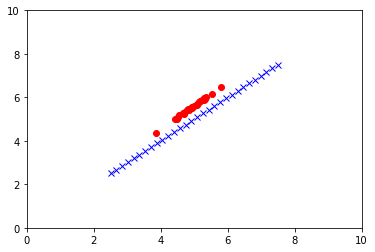

Epoch=4, Discriminator loss=1.3922840356826782, Generator loss=0.6994673609733582


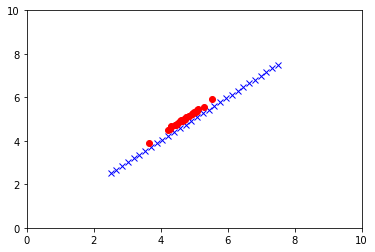

Epoch=5, Discriminator loss=1.3786420822143555, Generator loss=0.7348065972328186


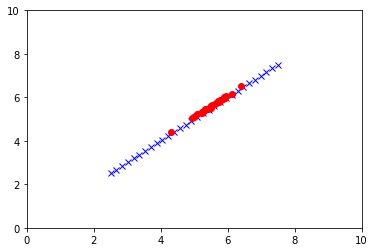

Epoch=6, Discriminator loss=1.3791067600250244, Generator loss=0.6620483994483948


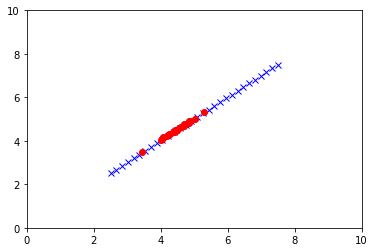

Epoch=7, Discriminator loss=1.3883013129234314, Generator loss=0.7702920436859131


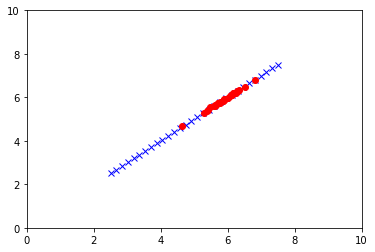

Epoch=8, Discriminator loss=1.4027888178825378, Generator loss=0.6409486532211304


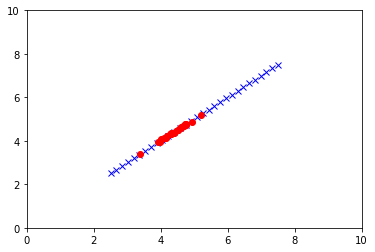

Epoch=9, Discriminator loss=1.4128007292747498, Generator loss=0.7470818758010864


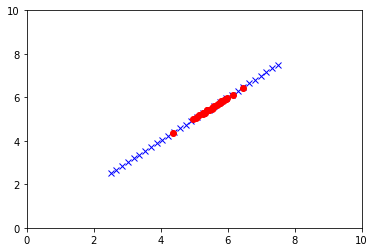

Epoch=10, Discriminator loss=1.3827651739120483, Generator loss=0.6983903646469116


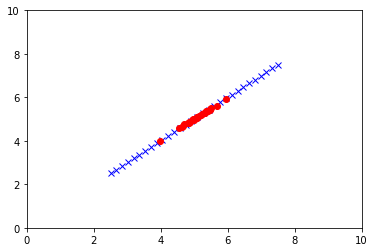

Epoch=11, Discriminator loss=1.3550625443458557, Generator loss=0.6800606846809387


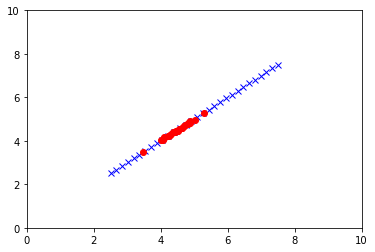

Epoch=12, Discriminator loss=1.3614674806594849, Generator loss=0.8109458684921265


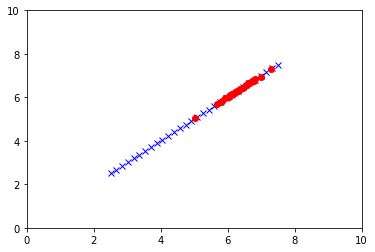

Epoch=13, Discriminator loss=1.4157356023788452, Generator loss=0.5888674855232239


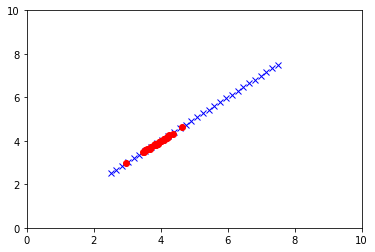

Epoch=14, Discriminator loss=1.443739652633667, Generator loss=0.7545626163482666


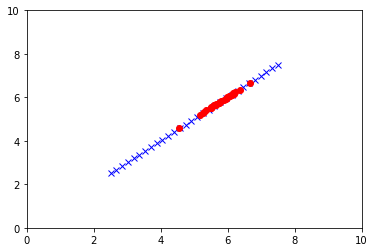

Epoch=15, Discriminator loss=1.3244879245758057, Generator loss=0.7508417367935181


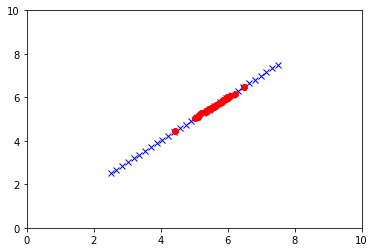

Epoch=16, Discriminator loss=1.2636395692825317, Generator loss=0.6462001800537109


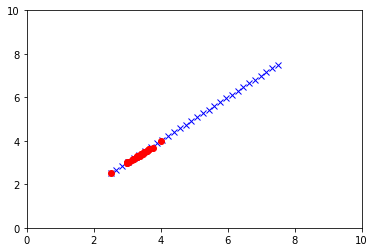

Epoch=17, Discriminator loss=1.5124391913414001, Generator loss=0.8882712125778198


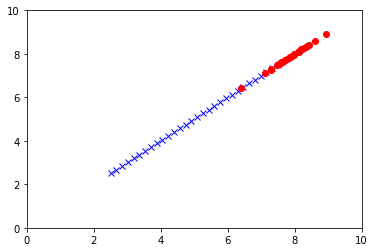

Epoch=18, Discriminator loss=1.5124066472053528, Generator loss=0.564290463924408


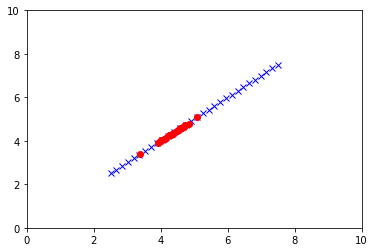

Epoch=19, Discriminator loss=1.273397982120514, Generator loss=0.6296595931053162


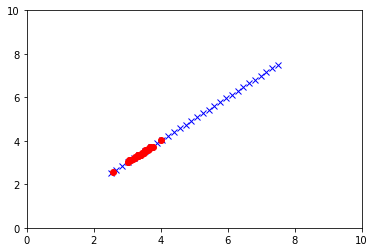

Epoch=20, Discriminator loss=1.5089653134346008, Generator loss=0.8017173409461975


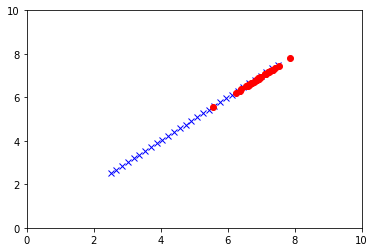

Epoch=21, Discriminator loss=1.3022897243499756, Generator loss=0.8264650702476501


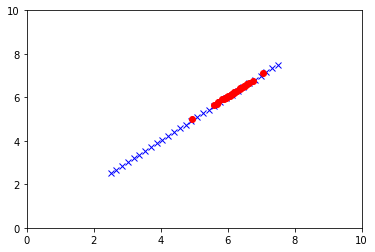

Epoch=22, Discriminator loss=1.421629548072815, Generator loss=0.5563646554946899


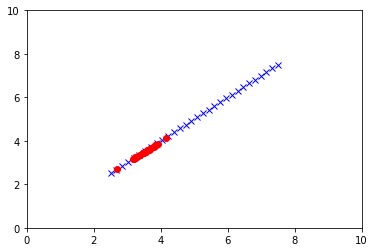

Epoch=23, Discriminator loss=1.3425378799438477, Generator loss=0.6742568612098694


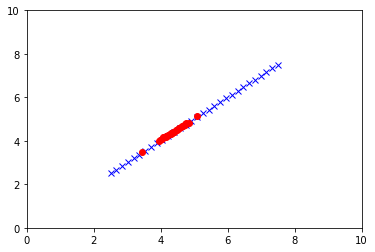

Epoch=24, Discriminator loss=1.4195616841316223, Generator loss=0.8190475702285767


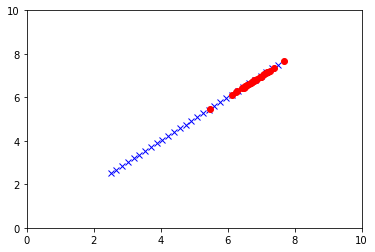

Epoch=25, Discriminator loss=1.343952476978302, Generator loss=0.7647059559822083


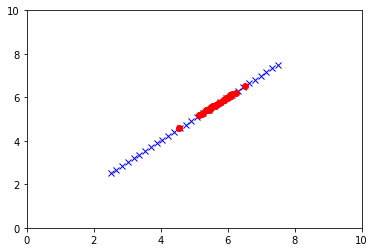

Epoch=26, Discriminator loss=1.4072083830833435, Generator loss=0.5923671126365662


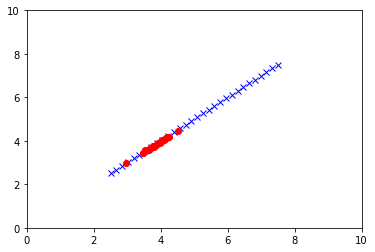

Epoch=27, Discriminator loss=1.3448505401611328, Generator loss=0.673907995223999


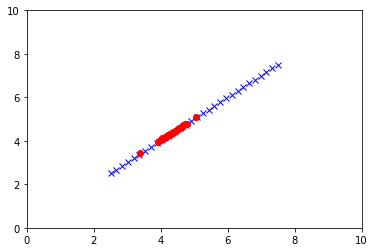

Epoch=28, Discriminator loss=1.415028989315033, Generator loss=0.7981662750244141


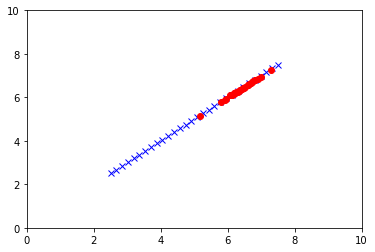

Epoch=29, Discriminator loss=1.332730233669281, Generator loss=0.7931588888168335


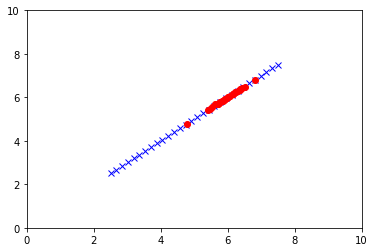

Epoch=30, Discriminator loss=1.410622775554657, Generator loss=0.5814265608787537


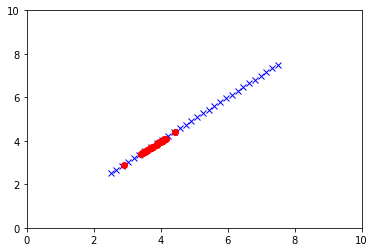

Epoch=31, Discriminator loss=1.322226643562317, Generator loss=0.6764724254608154


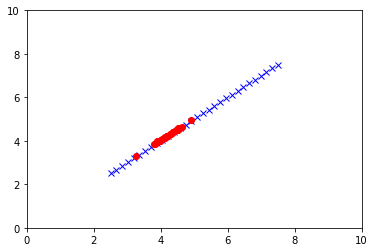

Epoch=32, Discriminator loss=1.4386621117591858, Generator loss=0.8196207880973816


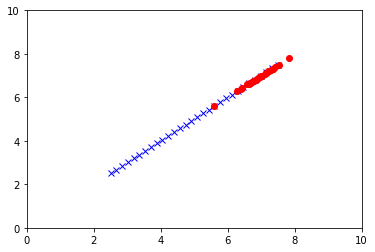

Epoch=33, Discriminator loss=1.296934187412262, Generator loss=0.811406135559082


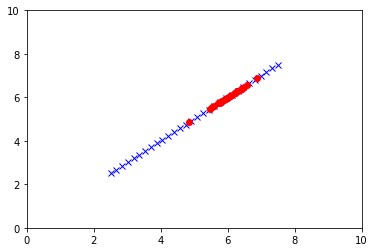

Epoch=34, Discriminator loss=1.3954280614852905, Generator loss=0.5505709052085876


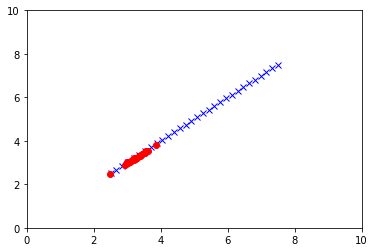

Epoch=35, Discriminator loss=1.307014286518097, Generator loss=0.6909207701683044


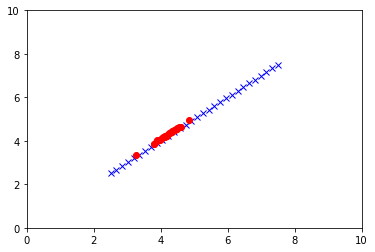

Epoch=36, Discriminator loss=1.453718662261963, Generator loss=0.8817367553710938


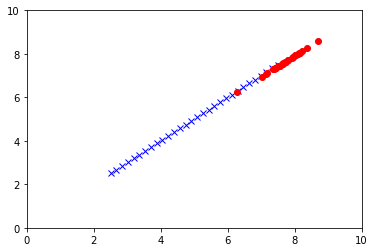

Epoch=37, Discriminator loss=1.2714897394180298, Generator loss=0.8484117388725281


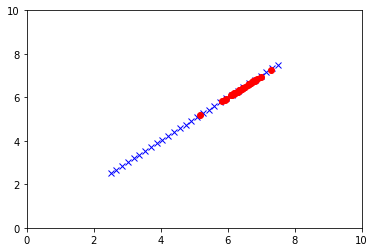

Epoch=38, Discriminator loss=1.447868824005127, Generator loss=0.5271252989768982


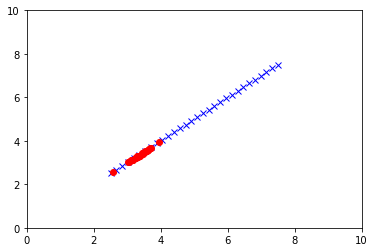

Epoch=39, Discriminator loss=1.3197149634361267, Generator loss=0.6189786791801453


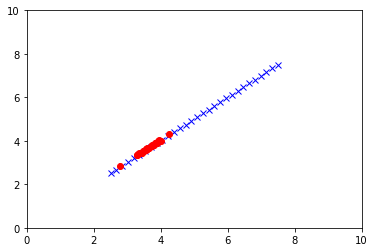

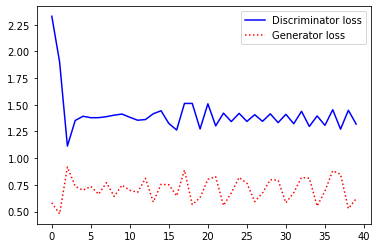

In [ ]:
def main():

    # Creating the GAN generator
    generator = Generator(30, 75, 2)
    generator_learning_rate = 0.001
    generator_loss = nn.BCELoss()
    generator_optimizer = optim.SGD(generator.parameters(), lr=generator_learning_rate, momentum=0.9)

    # Creating the GAN discriminator
    discriminator = Discriminator(2, 75, 1)
    discriminator_learning_rate = 0.001
    discriminator_loss = nn.BCELoss()
    discriminator_optimizer = optim.SGD(discriminator.parameters(), lr=discriminator_learning_rate, momentum=0.9)

    # Training epochs
    epochs = 40
    freeze_generator_steps = 1

    batch_size = 30
    number_of_batches = 100

    noise_for_plot = read_latent_space(batch_size)
    discriminator_loss_storage, generator_loss_storage = [], []

    print('Dataset loaded...')
    print('Starting adversarial GAN training for {} epochs.'.format(epochs))

    # Plot a little bit of trash
    input_real = get_data_samples(batch_size)
    generator_output = generator(noise_for_plot)
    plot_samples(input_real, generator_output, -1)

    for epoch in range(epochs):

        batch_number = 0

        # training discriminator
        while batch_number < number_of_batches: #len(data_iterator):

            # 1. Train the discriminator
            discriminator.zero_grad()
            # 1.1 Train discriminator on real data
            input_real = get_data_samples(batch_size)
            discriminator_real_out = discriminator(input_real.reshape(batch_size, 2))
            discriminator_real_loss = discriminator_loss(discriminator_real_out, real_data_target(batch_size))
            discriminator_real_loss.backward()
            # 1.2 Train the discriminator on data produced by the generator
            input_fake = read_latent_space(batch_size)
            generator_fake_out = generator(input_fake).detach()
            discriminator_fake_out = discriminator(generator_fake_out)
            discriminator_fake_loss = discriminator_loss(discriminator_fake_out, fake_data_target(batch_size))
            discriminator_fake_loss.backward()
            # 1.3 Optimizing the discriminator weights
            discriminator_optimizer.step()



            # 2. Train the generator
            if batch_number % freeze_generator_steps == 0:
              generator.zero_grad()
              # 2.1 Create fake data
              input_fake = read_latent_space(batch_size)
              generator_fake_out = generator(input_fake)
              # 2.2 Try to fool the discriminator with fake data
              discriminator_out_to_train_generator = discriminator(generator_fake_out)
              discriminator_loss_to_train_generator = generator_loss(discriminator_out_to_train_generator,
                                                                    real_data_target(batch_size))
              discriminator_loss_to_train_generator.backward()
              # 2.3 Optimizing the generator weights
              generator_optimizer.step()

            batch_number += 1

        discriminator_loss_storage.append(discriminator_fake_loss.item() + discriminator_real_loss.item())
        generator_loss_storage.append(discriminator_loss_to_train_generator.item())
        print('Epoch={}, Discriminator loss={}, Generator loss={}'.format(epoch, discriminator_loss_storage[-1], generator_loss_storage[-1]))

        if epoch % 1 == 0:
            generator_output = generator(noise_for_plot)
            plot_samples(input_real, generator_output, epoch)

    plot_loss_evolution(discriminator_loss_storage, generator_loss_storage)

main()
